In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas
import numpy
import matplotlib
import seaborn
import sklearn

print("All libraries installed successfully")

All libraries installed successfully


In [3]:
#libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
#for ml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [5]:
#for_evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

In [6]:
df = pd.read_csv("../data/bank_churn.csv")

In [7]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [8]:
df.tail()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


In [9]:
df.shape

(10000, 14)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [11]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [12]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [13]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df = df.drop_duplicates()

In [16]:
df["Exited"].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [17]:
#This gives the percentage of customers who stayed/left
df["Exited"].value_counts(normalize=True) * 100

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64

In [18]:
#Churn by gender
pd.crosstab(df["Gender"], df["Exited"])

Exited,0,1
Gender,,
Female,3404,1139
Male,4559,898


In [19]:
#percentage
pd.crosstab(
    df["Gender"],
    df["Exited"],
    normalize="index"
) * 100

Exited,0,1
Gender,,
Female,74.928461,25.071539
Male,83.544072,16.455928


In [20]:
#Churn by geography
pd.crosstab(
    df["Geography"],
    df["Exited"]
)

Exited,0,1
Geography,,
France,4204,810
Germany,1695,814
Spain,2064,413


In [21]:
#Churn by active membership
pd.crosstab(
    df["IsActiveMember"],
    df["Exited"]
)

Exited,0,1
IsActiveMember,,
0,3547,1302
1,4416,735


In [22]:
#Churn by number of products
pd.crosstab(
    df["NumOfProducts"],
    df["Exited"]
)

Exited,0,1
NumOfProducts,,
1,3675,1409
2,4242,348
3,46,220
4,0,60


In [23]:
#Churn by credit card
pd.crosstab(
    df["HasCrCard"],
    df["Exited"]
)

Exited,0,1
HasCrCard,,
0,2332,613
1,5631,1424


In [24]:
#Average balance by churn
df.groupby("Exited")["Balance"].mean()

Exited
0    72745.296779
1    91108.539337
Name: Balance, dtype: float64

In [25]:
#Average age by churn
df.groupby("Exited")["Age"].mean()

Exited
0    37.408389
1    44.837997
Name: Age, dtype: float64

In [26]:
#Average credit score by churn
df.groupby("Exited")["CreditScore"].mean()

Exited
0    651.853196
1    645.351497
Name: CreditScore, dtype: float64

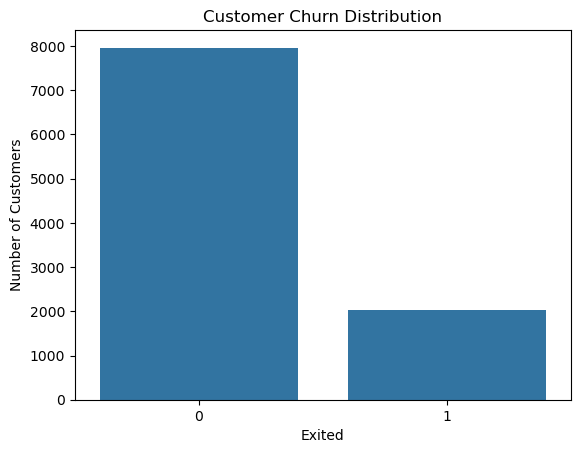

In [27]:
#Graph 1 — Churn distribution
sns.countplot(x="Exited", data=df)

plt.title("Customer Churn Distribution")
plt.xlabel("Exited")
plt.ylabel("Number of Customers")

plt.show()

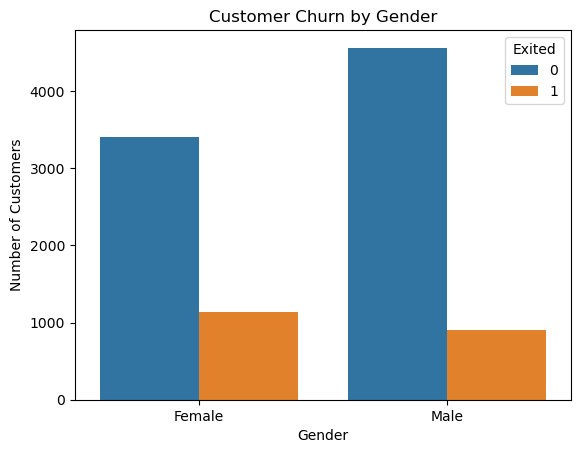

In [28]:
#Graph 2 — Churn by gender
sns.countplot(
    x="Gender",
    hue="Exited",
    data=df
)

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

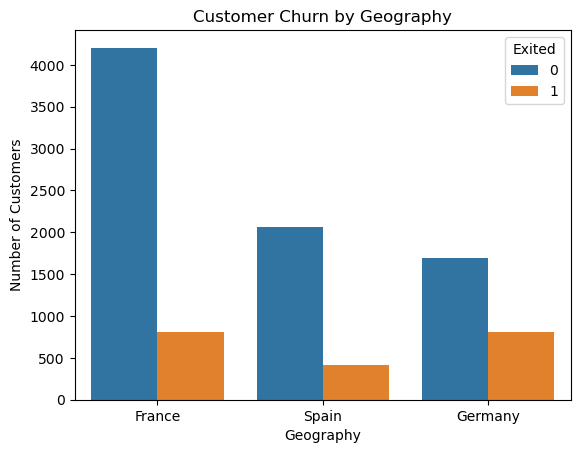

In [29]:
#Graph 3 — Churn by geography
sns.countplot(
    x="Geography",
    hue="Exited",
    data=df
)

plt.title("Customer Churn by Geography")
plt.xlabel("Geography")
plt.ylabel("Number of Customers")

plt.show()

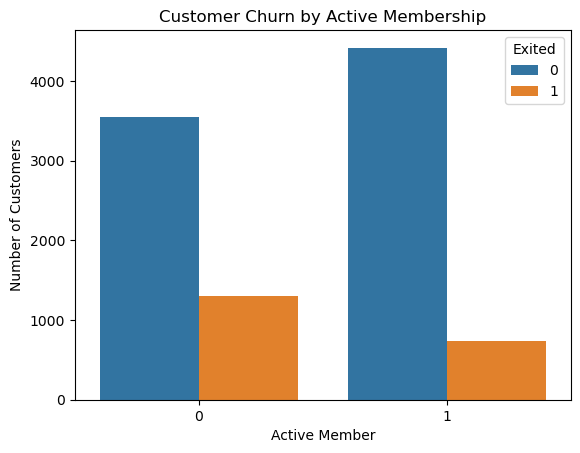

In [30]:
#Graph 4 — Churn by active membership
sns.countplot(
    x="IsActiveMember",
    hue="Exited",
    data=df
)

plt.title("Customer Churn by Active Membership")
plt.xlabel("Active Member")
plt.ylabel("Number of Customers")

plt.show()

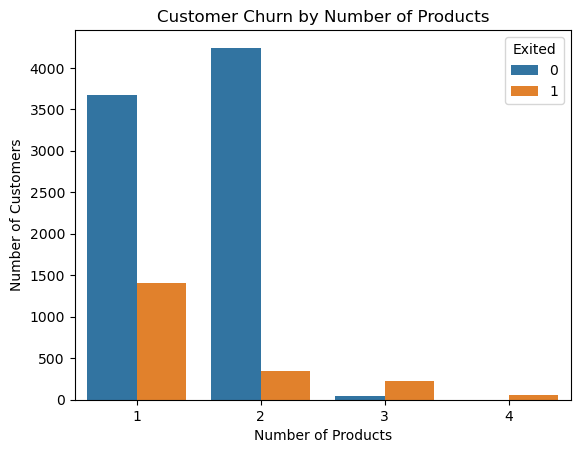

In [31]:
#Graph 5 — Churn by products
sns.countplot(
    x="NumOfProducts",
    hue="Exited",
    data=df
)

plt.title("Customer Churn by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Number of Customers")

plt.show()

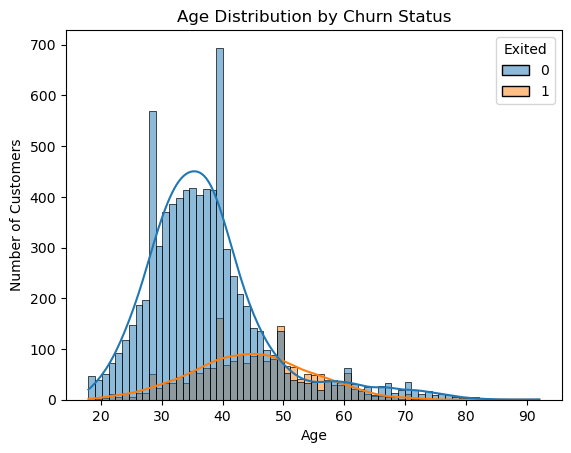

In [32]:
#Graph 6 — Age distribution
sns.histplot(
    data=df,
    x="Age",
    hue="Exited",
    kde=True
)

plt.title("Age Distribution by Churn Status")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

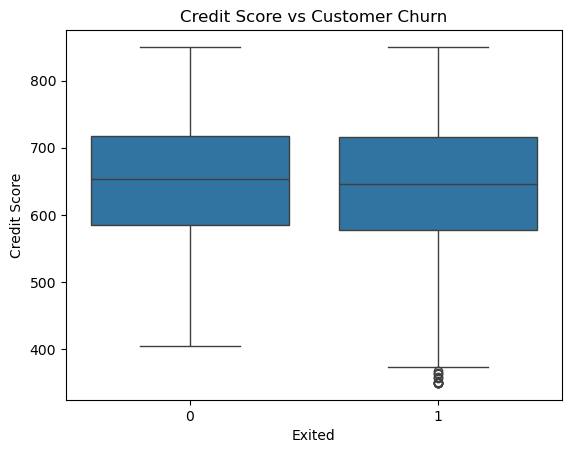

In [33]:
#Graph 7 — Credit score
sns.boxplot(
    x="Exited",
    y="CreditScore",
    data=df
)

plt.title("Credit Score vs Customer Churn")
plt.xlabel("Exited")
plt.ylabel("Credit Score")

plt.show()

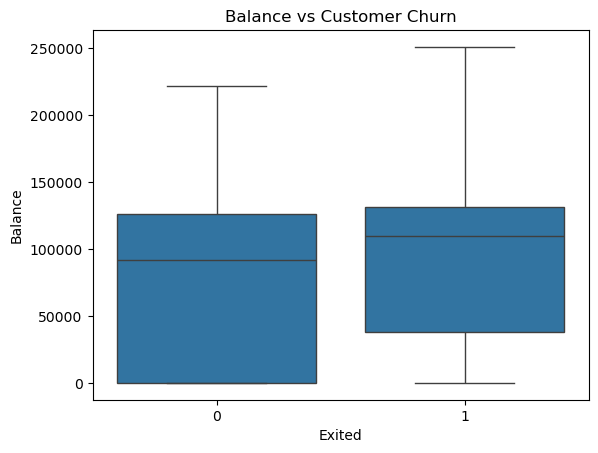

In [34]:
#Graph 8 — Balance
sns.boxplot(
    x="Exited",
    y="Balance",
    data=df
)

plt.title("Balance vs Customer Churn")
plt.xlabel("Exited")
plt.ylabel("Balance")

plt.show()

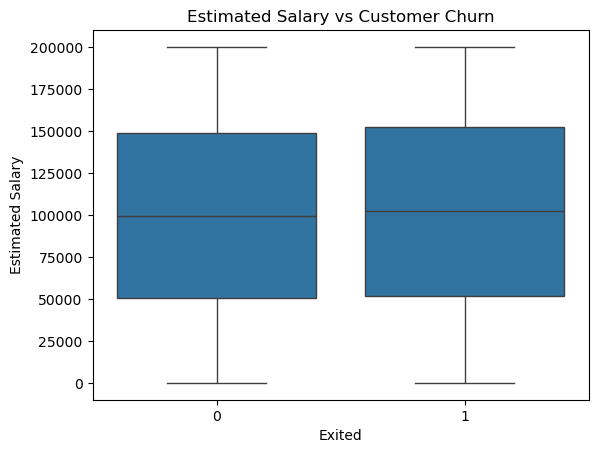

In [35]:
#Graph 9 — Salary
sns.boxplot(
    x="Exited",
    y="EstimatedSalary",
    data=df
)

plt.title("Estimated Salary vs Customer Churn")
plt.xlabel("Exited")
plt.ylabel("Estimated Salary")

plt.show()

In [36]:
#Correlation analysis
numeric_data = df.select_dtypes(include=np.number)

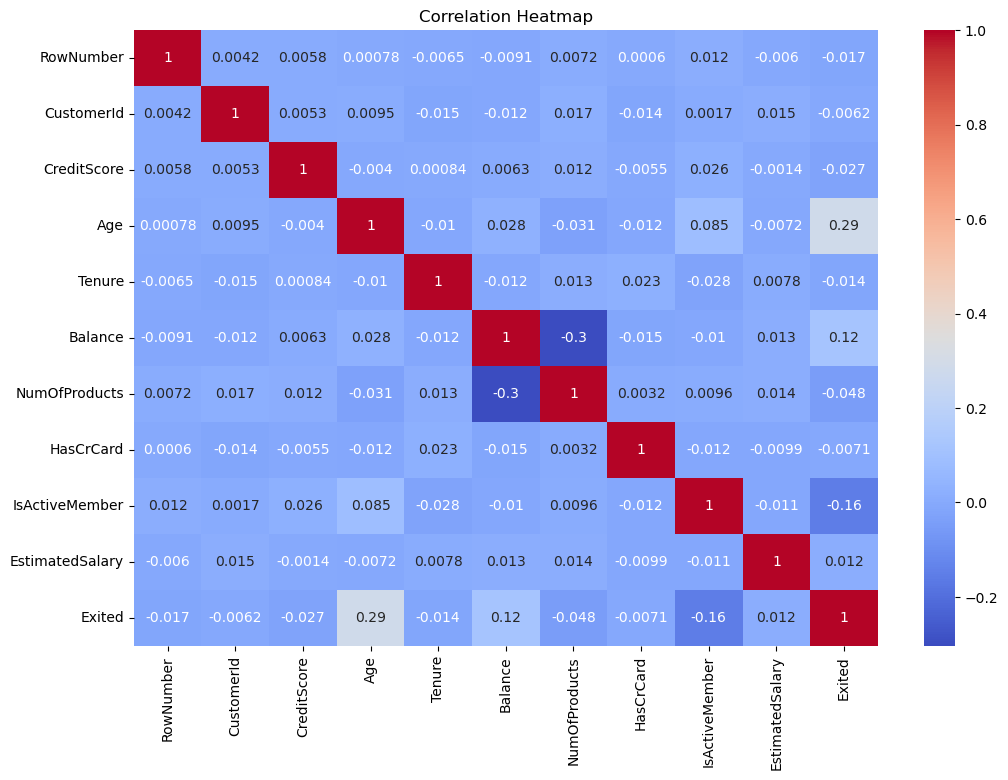

In [37]:
#EDA visualization
plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [38]:
#Feature selection for Machine Learning
df.columns


Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [39]:
X = df.drop(
    ["Exited", "RowNumber", "CustomerId", "Surname"],
    axis=1,
    errors="ignore"
)

In [40]:
y = df["Exited"]

In [41]:
#Convert categorical data
X = pd.get_dummies(
    X,
    columns=["Geography", "Gender"],
    drop_first=True
)

In [42]:
X.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False


In [43]:
#Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [44]:
#Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [45]:
#Train Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [46]:
#predict
logistic_prediction = logistic_model.predict(
    X_test_scaled
)

In [47]:
#Evaluate Logistic Regression
print(
    "Accuracy:",
    accuracy_score(y_test, logistic_prediction)
)

print(
    "Precision:",
    precision_score(y_test, logistic_prediction)
)

print(
    "Recall:",
    recall_score(y_test, logistic_prediction)
)

print(
    "F1 Score:",
    f1_score(y_test, logistic_prediction)
)

Accuracy: 0.808
Precision: 0.5891472868217055
Recall: 0.18673218673218672
F1 Score: 0.2835820895522388


In [48]:
#ROC-AUC:
logistic_probability = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        logistic_probability
    )
)

ROC-AUC: 0.7747778595236223


In [49]:
#Decision Tree
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

decision_tree.fit(
    X_train,
    y_train
)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [50]:
#prediction
tree_prediction = decision_tree.predict(X_test)

In [51]:
#evalutaion
print(
    "Decision Tree Accuracy:",
    accuracy_score(
        y_test,
        tree_prediction
    )
)

Decision Tree Accuracy: 0.856


In [52]:
#Random Forest
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(
    X_train,
    y_train
)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [53]:
#prediction
forest_prediction = random_forest.predict(
    X_test
)

In [54]:
#probability
forest_probability = random_forest.predict_proba(
    X_test
)[:, 1]

In [56]:
# Compare all models

models = {
    "Logistic Regression": logistic_prediction,
    "Decision Tree": tree_prediction,
    "Random Forest": forest_prediction
}

model_probabilities = {
    "Logistic Regression": logistic_probability,
    "Decision Tree": decision_tree.predict_proba(X_test)[:, 1],
    "Random Forest": forest_probability
}

model_results = []

for name, prediction in models.items():

    probability = model_probabilities[name]

    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction, zero_division=0),
        "Recall": recall_score(y_test, prediction, zero_division=0),
        "F1 Score": f1_score(y_test, prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probability)
    })

model_comparison = pd.DataFrame(model_results).sort_values(
    by="F1 Score",
    ascending=False
)

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,0.8645,0.783333,0.461916,0.581144,0.852629
1,Decision Tree,0.8560,0.787440,0.400491,0.530945,0.842254
0,Logistic Regression,0.8080,0.589147,0.186732,0.283582,0.774778


In [57]:
# Select the best model based on F1 Score
best_model_name = model_comparison.iloc[0]["Model"]
print("Best model:", best_model_name)


Best model: Random Forest


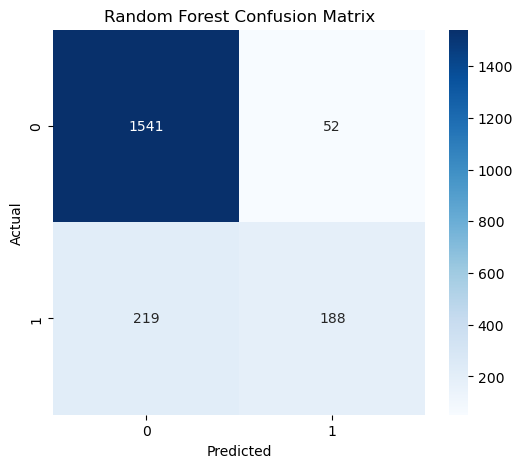

In [58]:
# Use the best model for final predictions
if best_model_name == "Logistic Regression":
    final_model = logistic_model
    final_prediction = logistic_prediction
    final_probability = logistic_probability
    final_test_data = X_test_scaled
elif best_model_name == "Decision Tree":
    final_model = decision_tree
    final_prediction = tree_prediction
    final_probability = model_probabilities["Decision Tree"]
    final_test_data = X_test
else:
    final_model = random_forest
    final_prediction = forest_prediction
    final_probability = forest_probability
    final_test_data = X_test

cm = confusion_matrix(y_test, final_prediction)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"{best_model_name} Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [59]:
# Classification Report
print(classification_report(y_test, final_prediction, zero_division=0))


              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.78      0.46      0.58       407

    accuracy                           0.86      2000
   macro avg       0.83      0.71      0.75      2000
weighted avg       0.86      0.86      0.85      2000



In [60]:
# Feature Importance (available for tree-based models)
if best_model_name in ["Decision Tree", "Random Forest"]:
    importance = pd.Series(
        final_model.feature_importances_,
        index=X.columns
    ).sort_values(ascending=False)
    print(importance)
else:
    # Logistic Regression uses coefficients instead of tree feature importance
    importance = pd.Series(
        np.abs(final_model.coef_[0]),
        index=X.columns
    ).sort_values(ascending=False)
    print(importance)


Age                  0.236485
EstimatedSalary      0.147016
CreditScore          0.142756
Balance              0.141756
NumOfProducts        0.130410
Tenure               0.081817
IsActiveMember       0.039933
Geography_Germany    0.028923
HasCrCard            0.018799
Gender_Male          0.018483
Geography_Spain      0.013622
dtype: float64


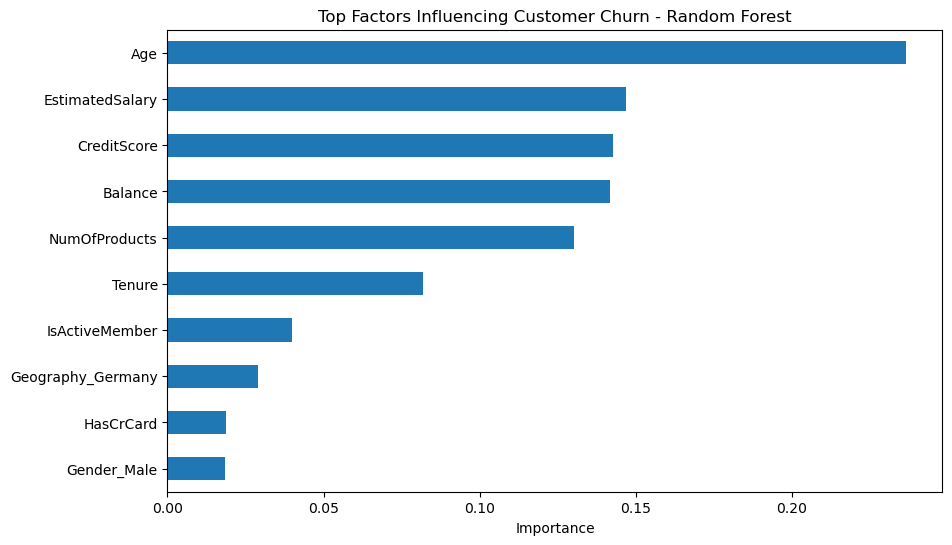

In [61]:
# Top factors influencing customer churn
plt.figure(figsize=(10, 6))
importance.head(10).sort_values().plot(kind="barh")
plt.title(f"Top Factors Influencing Customer Churn - {best_model_name}")
plt.xlabel("Importance")
plt.show()


In [62]:
# Generate final predictions for the test customers
predicted_probability = final_probability
predicted_class = final_prediction


In [63]:
# Keep the original customer information
prediction_results = df.loc[X_test.index].copy()


In [64]:
prediction_results["ChurnProbability"] = predicted_probability
prediction_results["PredictedChurn"] = predicted_class


In [65]:
# Create Risk Category
def risk_category(probability):
    if probability < 0.30:
        return "Low Risk"
    elif probability < 0.60:
        return "Medium Risk"
    else:
        return "High Risk"

prediction_results["RiskCategory"] = prediction_results["ChurnProbability"].apply(risk_category)


In [74]:
# Save the final CSV for Tableau
prediction_results.to_csv(
    "../output/customer_predictions.csv",
    index=False
)
print("Saved: ../output/customer_predictions.csv")


Saved: ../output/customer_predictions.csv


In [67]:
# Verify the generated file
prediction_results.head()


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,ChurnProbability,PredictedChurn,RiskCategory
5702,5703,15749540,Hsiung,585,France,Male,36,7,0.00,2,1,0,94283.09,0,0.08,0,Low Risk
3667,3668,15807340,O'Donnell,525,Germany,Male,33,4,131023.76,2,0,0,55072.93,0,0.02,0,Low Risk
1617,1618,15801062,Matthews,557,Spain,Female,40,4,0.00,2,0,1,105433.53,0,0.04,0,Low Risk
5673,5674,15572801,Krischock,639,Spain,Male,34,5,139393.19,2,0,0,33950.08,0,0.02,0,Low Risk
4272,4273,15600708,Calabresi,640,Spain,Female,34,3,77826.80,1,1,1,168544.85,0,0.09,0,Low Risk


In [68]:
prediction_results.shape


(2000, 17)

In [69]:
prediction_results["RiskCategory"].value_counts()


RiskCategory
Low Risk       1504
Medium Risk     314
High Risk       182
Name: count, dtype: int64

In [70]:
#Save the final CSV
prediction_results.to_csv(
    "../output/customer_predictions.csv",
    index=False
)

In [71]:
#Check the generated file
prediction_results.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,ChurnProbability,PredictedChurn,RiskCategory
5702,5703,15749540,Hsiung,585,France,Male,36,7,0.00,2,1,0,94283.09,0,0.08,0,Low Risk
3667,3668,15807340,O'Donnell,525,Germany,Male,33,4,131023.76,2,0,0,55072.93,0,0.02,0,Low Risk
1617,1618,15801062,Matthews,557,Spain,Female,40,4,0.00,2,0,1,105433.53,0,0.04,0,Low Risk
5673,5674,15572801,Krischock,639,Spain,Male,34,5,139393.19,2,0,0,33950.08,0,0.02,0,Low Risk
4272,4273,15600708,Calabresi,640,Spain,Female,34,3,77826.80,1,1,1,168544.85,0,0.09,0,Low Risk


In [72]:
prediction_results.shape

(2000, 17)

In [73]:
prediction_results["RiskCategory"].value_counts()

RiskCategory
Low Risk       1504
Medium Risk     314
High Risk       182
Name: count, dtype: int64